<p style="align: center;"><img align=center src="https://drive.google.com/uc?export=view&id=1I8kDikouqpH4hf7JBiSYAeNT2IO52T-T" width=600 height=480/></p>
<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h3 style="text-align: center;"><b>Домашнее задание. Generative adversarial networks</b></h3>



В этом домашнем задании вы обучите GAN генерировать лица людей и посмотрите на то, как можно оценивать качество генерации

In [1]:
import os
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
import torchvision.transforms as tt
import torch
import torch.nn as nn
import cv2
from tqdm.notebook import tqdm
from torchvision.utils import save_image
from torchvision.utils import make_grid
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

sns.set(style='darkgrid', font_scale=1.2)

## Часть 1. Подготовка данных (1 балл)

В качестве обучающей выборки возьмем часть датасета [Flickr Faces](https://github.com/NVlabs/ffhq-dataset), который содержит изображения лиц людей в высоком разрешении (1024х1024). Оригинальный датасет очень большой, поэтому мы возьмем его часть. Скачать датасет можно [здесь](https://www.kaggle.com/datasets/tommykamaz/faces-dataset-small?resource=download-directory) и  [здесь](https://drive.google.com/file/d/1inyvLrN5wKBGCxQ4znMKBc64uL4uP_2x/view?usp=drive_link)

Давайте загрузим наши изображения. Напишите функцию, которая строит DataLoader для изображений, при этом меняя их размер до нужного значения (размер 1024 слишком большой, поэтому мы рекомендуем взять размер 128 либо немного больше)

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("tommykamaz/faces-dataset-small")

print("Path to dataset files:", path)

100%|██████████| 3.99G/3.99G [01:01<00:00, 69.3MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/tommykamaz/faces-dataset-small/versions/1


In [3]:
image_size = 128
stats = (0.5, 0.5, 0.5), (0.5, 0.5, 0.5)
train_ds = ImageFolder(path, transform=tt.Compose([
    tt.Resize(image_size),
    tt.CenterCrop(image_size), # ск всего не нужно
    tt.ToTensor(),
    tt.Normalize(*stats)
    ])
)

In [4]:
# torch.cuda.empty_cache()

In [5]:
train_dl = DataLoader(train_ds, batch_size = 32, shuffle=True, num_workers=2, pin_memory=True)
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')


In [6]:
for item in next(iter(train_dl)):
  print(item.shape)
  # print(item[1])


# print(next(iter(train_dl))[0])

torch.Size([32, 3, 128, 128])
torch.Size([32])


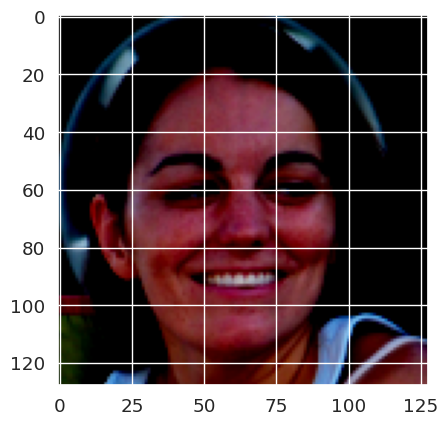

In [7]:
plt.imshow(next(iter(train_dl))[0][0].permute(1,2,0))

In [8]:
# def get_dataloader(image_size, batch_size):
#   """
#   Builds dataloader for training data.
#   Use tt.Compose and tt.Resize for transformations
#   :param image_size: height and wdith of the image
#   :param batch_size: batch_size of the dataloader
#   :returns: DataLoader object
#   """
#   # TODO: resize images, convert them to tensors and build dataloader
#   pass

In [9]:


#TODO: build dataloader and transfer it to device

## Часть 2. Построение и обучение модели (4 балла)

Сконструируйте генератор и дискриминатор. Помните, что:
* дискриминатор принимает на вход изображение (тензор размера `3 x image_size x image_size`) и выдает вероятность того, что изображение настоящее (тензор размера 1)

* генератор принимает на вход тензор шумов размера `latent_size x 1 x 1` и генерирует изображение размера `3 x image_size x image_size`

In [54]:
from torch.nn.modules.activation import Sigmoid
class Discriminator(nn.Module):
  def __init__(self):
    super(Discriminator, self).__init__()
    self.discriminator = nn.Sequential(
        # in: 128x128
        nn.Conv2d(3, 16, kernel_size = 4, stride = 2, padding = 1, bias = False),
        nn.BatchNorm2d(16),
        nn.ReLU(),

        # in: 64x64
        nn.Conv2d(16, 32, kernel_size = 4, stride = 2, padding = 1, bias = False),
        nn.BatchNorm2d(32),
        nn.ReLU(),

        # in: 32x32
        nn.Conv2d(32, 64, kernel_size = 4, stride = 2, padding = 1, bias = False),
        nn.BatchNorm2d(64),
        nn.ReLU(),

        # in: 16x16
        nn.Conv2d(64, 128, kernel_size = 4, stride = 2, padding = 1, bias = False),
        nn.BatchNorm2d(128),
        nn.ReLU(),

        # in: 8x8
        nn.Conv2d(128, 256, kernel_size = 4, stride = 2, padding = 1, bias = False),
        nn.BatchNorm2d(256),
        nn.ReLU(),

        # in: 4x4
        nn.Conv2d(256, 1, kernel_size = 4, stride = 1, padding = 0, bias = False),

        # in:1x1
        nn.Flatten(),
        nn.Sigmoid(),
          )

  def forward(self, x):
      out = self.discriminator(x)
      return out



In [55]:
discriminator = Discriminator()

In [56]:
test_in = torch.rand(32,3,128,128)

In [57]:
discriminator(test_in).shape

torch.Size([32, 1])

In [130]:
latent_size = 128
class Generator(nn.Module):
  def __init__(self, latent_size = latent_size):
    super(Generator, self).__init__()
    self.generator = nn.Sequential(
        #in latent x 1 x 1
        nn.ConvTranspose2d(latent_size, 256, kernel_size = 4, bias = False),
        nn.ReLU(),
        nn.BatchNorm2d(256),
        #out 512x4x4

        nn.ConvTranspose2d(256, 256, kernel_size=4, padding =1, stride = 2, bias = False),
        nn.ReLU(),
        nn.BatchNorm2d(256),
        # out 256x8x8

        nn.ConvTranspose2d(256, 128, kernel_size=4, padding =1, stride = 2, bias = False),
        nn.ReLU(),
        nn.BatchNorm2d(128),
        #out 128x16x16

        nn.ConvTranspose2d(128, 128, kernel_size=4, padding =1, stride = 2, bias = False),
        nn.ReLU(),
        nn.BatchNorm2d(128),
        #out 64x128x128

        nn.ConvTranspose2d(128, 64, kernel_size=4, padding =1, stride = 2, bias = False),
        nn.ReLU(),
        nn.BatchNorm2d(64),

        #out 32x64x64
          nn.ConvTranspose2d(64, 32, kernel_size=3, padding =1, stride = 1, bias = False),
        nn.ReLU(),
        nn.BatchNorm2d(32),
        #out 32x64x64

          nn.ConvTranspose2d(32, 32, kernel_size=3, padding =1, stride = 1, bias = False),
        nn.ReLU(),
        nn.BatchNorm2d(32),

        #out 32x64x64
        nn.ConvTranspose2d(32, 3, kernel_size=4, padding =1, stride = 2, bias = False),
        nn.Tanh(),
        #out 3x128x128
    )

  def forward(self, x):
    out = self.generator(x)
    return out

In [131]:
generator = Generator(latent_size = latent_size)

In [132]:
test_in = torch.rand(32,latent_size, 1, 1)
test_out = generator(test_in)


In [133]:
test_out.shape

torch.Size([32, 3, 128, 128])

In [134]:
generator = generator.to(device)
discriminator = discriminator.to(device)

Перейдем теперь к обучению нашего GANа. Алгоритм обучения следующий:
1. Учим дискриминатор:
  * берем реальные изображения и присваиваем им метку 1
  * генерируем изображения генератором и присваиваем им метку 0
  * обучаем классификатор на два класса

2. Учим генератор:
  * генерируем изображения генератором и присваиваем им метку 0
  * предсказываем дискриминаторором, реальное это изображение или нет


В качестве функции потерь берем бинарную кросс-энтропию

In [135]:
lr = 0.001

model = {
    "discriminator": discriminator,
    "generator": generator
}

criterion = {
    "discriminator": nn.BCELoss(),
    "generator": nn.BCELoss()
}



In [143]:
def fit(model, criterion, epochs, lr, save=True):

  optimizer = {
    "discriminator": torch.optim.Adam(model["discriminator"].parameters(),
                                      lr=lr, betas=(0.5, 0.999)),
    "generator": torch.optim.Adam(model["generator"].parameters(),
                                  lr=lr, betas=(0.5, 0.999))
  }

  d_pred_per_epoch = []
  d_pred_fake_per_epoch = []
  d_loss_per_epoch = []
  g_loss_per_epoch = []

  # train one epoch
  for epoch in range(epochs):
    d_pred_per_batch=[]
    d_pred_fake_per_batch=[]
    d_loss_per_batch=[]
    g_loss_per_batch=[]

    for real_images, _ in tqdm(train_dl):

      real_images = real_images.to(device)

      model['discriminator'].train()
      model['generator'].train()

      # zero grad
      optimizer['discriminator'].zero_grad()

      # real targets
      real_targets = torch.ones(real_images.size(0), 1, device=device)

      # prediction on real images
      d_pred = model['discriminator'](real_images)
      real_loss = criterion['discriminator'](d_pred, real_targets)

      # generate fake images
      latent_seed = torch.rand(real_images.size(0), latent_size, 1, 1, device = device)
      fake_images = model['generator'](latent_seed)

      # discriminator predict on fake images and calc loss
      d_pred_fake = model['discriminator'](fake_images)
      fake_targets = torch.zeros(real_images.size(0), 1, device=device)
      fake_loss = criterion['discriminator'](d_pred_fake, fake_targets)

      # calc sum of loss and train
      d_loss = real_loss + fake_loss
      d_loss.backward()
      optimizer['discriminator'].step()

      # train generator
      model['generator'].zero_grad()

      # generate fake images
      latent_seed = torch.rand(real_images.size(0), latent_size, 1, 1, device = device)
      fake_images = model['generator'](latent_seed)

      # fake prediction
      preds = model['discriminator'](fake_images)
      target_preds = torch.ones(real_images.size(0), 1, device = device)

      # calculate loss (predictions, targets)
      g_loss = criterion['generator'](preds, target_preds)
      # update weights
      g_loss.backward()
      optimizer['generator'].step()

      d_pred_per_batch.append(d_pred.mean().item())
      d_pred_fake_per_batch.append(d_pred_fake.mean().item())
      d_loss_per_batch.append(d_loss.item())
      g_loss_per_batch.append(g_loss.item())

    d_pred_per_epoch.append(np.mean(d_pred_per_batch))
    d_pred_fake_per_epoch.append(np.mean(d_pred_fake_per_batch))
    d_loss_per_epoch.append(np.mean(d_loss_per_batch))
    g_loss_per_epoch.append(np.mean(g_loss_per_batch))

  if save:
    import pandas as pd
    from google.colab import files

    # Save metrics data
    history_df = pd.DataFrame({
        'd_loss': d_loss_per_epoch,
        'g_loss': g_loss_per_epoch,
        'd_pred_real': d_pred_per_epoch,
        'd_pred_fake': d_pred_fake_per_epoch
    })
    history_df.to_csv('gan_training_history.csv', index=False)

    # Save final fake image samples
    with torch.no_grad():
      fixed_latent = torch.randn(64, latent_size, 1, 1, device=device)
      sample_fakes = model['generator'](fixed_latent).cpu()
      # Denormalize
      sample_fakes = sample_fakes * stats[1][0] + stats[0][0]
      save_image(make_grid(sample_fakes, nrow=8), 'final_fake_images.png')

    print("Training history and generated images have been saved locally in Google Colab workspace.")
    try:
        files.download('gan_training_history.csv')
        files.download('final_fake_images.png')
        print("Successfully initiated downloads to your laptop.")
    except Exception as e:
        print("Could not trigger automatic browser download, you can find the files 'gan_training_history.csv' and 'final_fake_images.png' in the left file explorer sidebar to download manually.")

  return d_pred_per_epoch, d_pred_fake_per_epoch, d_loss_per_epoch, g_loss_per_epoch

In [144]:
epochs = 4
d_pred_per_epoch, d_pred_fake_per_epoch, d_loss_per_epoch, g_loss_per_epoch = fit(model, criterion, epochs, lr)

  0%|          | 0/99 [00:00<?, ?it/s]

  0%|          | 0/99 [00:00<?, ?it/s]

  0%|          | 0/99 [00:00<?, ?it/s]

KeyboardInterrupt: 

Постройте графики лосса для генератора и дискриминатора. Что вы можете сказать про эти графики?

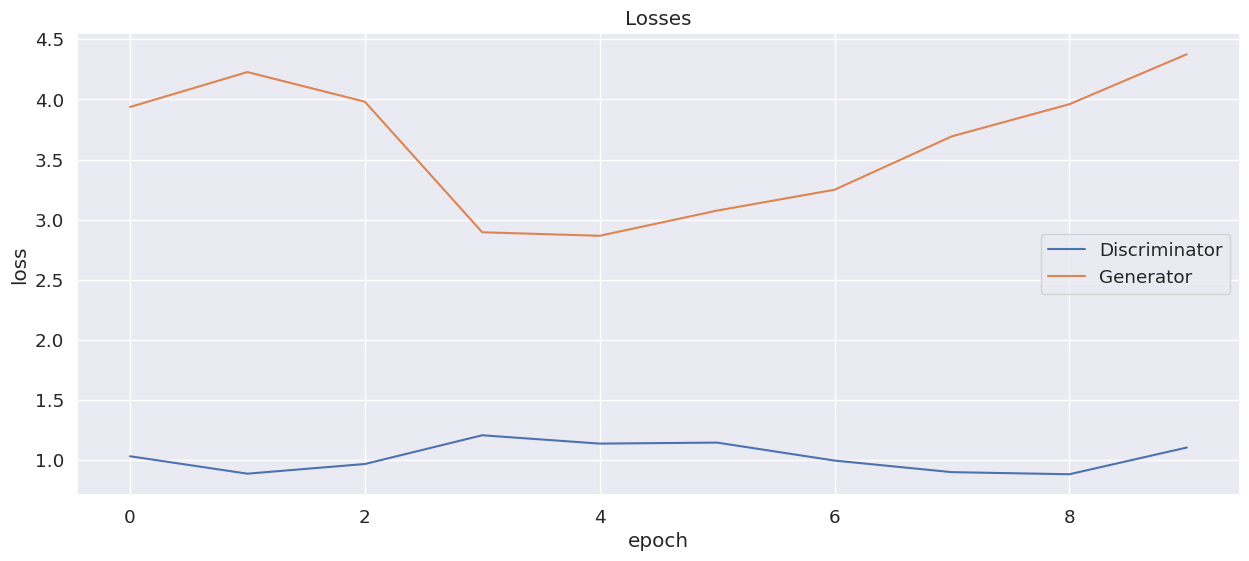

In [138]:
plt.figure(figsize=(15, 6))
plt.plot(d_loss_per_epoch, '-')
plt.plot(g_loss_per_epoch, '-')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['Discriminator', 'Generator'])
plt.title('Losses');

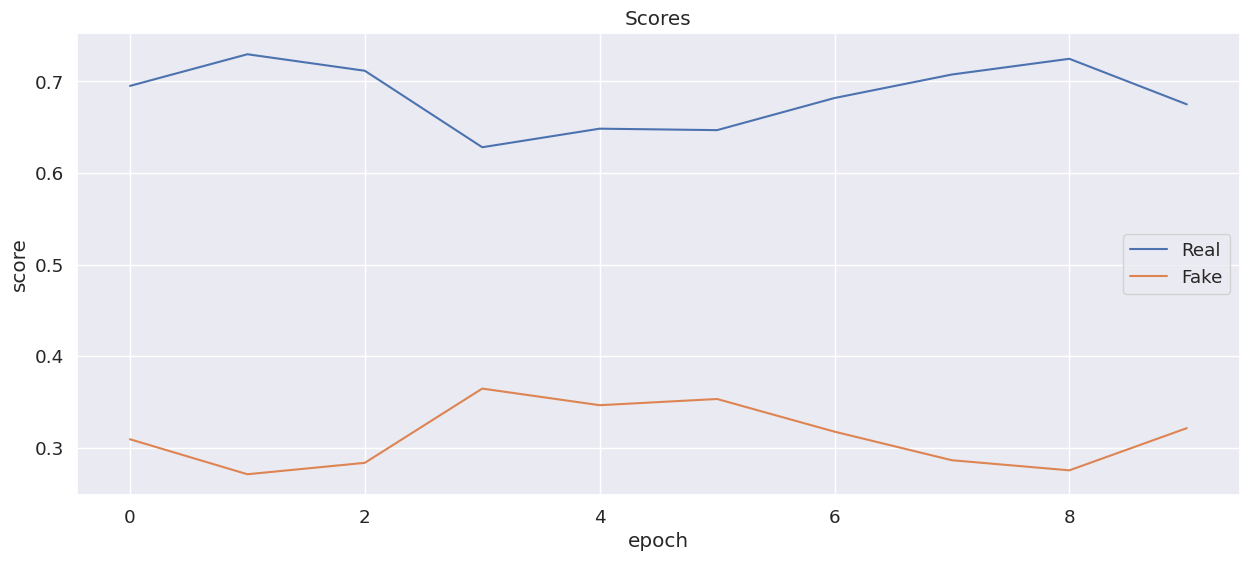

In [139]:
plt.figure(figsize=(15, 6))

plt.plot(d_pred_per_epoch, '-')
plt.plot(d_pred_fake_per_epoch, '-')
plt.xlabel('epoch')
plt.ylabel('score')
plt.legend(['Real', 'Fake'])
plt.title('Scores');

In [140]:


test_in = torch.rand(32, latent_size, 1, 1).to(device)
fake_images = model['generator'](test_in)
fake_images = fake_images.to('cpu')

In [141]:
def denorm(img_tensors):
    return img_tensors * stats[1][0] + stats[0][0]

def show_images(images, nmax=64):
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.set_xticks([]); ax.set_yticks([])
    ax.imshow(make_grid(denorm(images.detach()[:nmax]), nrow=8).permute(1, 2, 0))

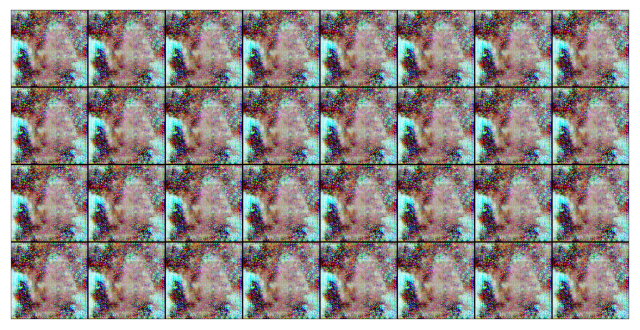

In [142]:
show_images(fake_images, 32)

In [82]:
denorm(fake_images[1,1,:,:]).max()

tensor(0.9999, grad_fn=<MaxBackward1>)

## Часть 3. Генерация изображений

Теперь давайте оценим качество получившихся изображений. Напишите функцию, которая выводит изображения, сгенерированные нашим генератором

In [ ]:
n_images = 4

fixed_latent = torch.randn(n_images, latent_size, 1, 1, device=device)
fake_images = model["generator"](fixed_latent)

In [ ]:
def show_images(generated):
  # TODO: show generated images
  pass

Как вам качество получившихся изображений?

## Часть 4. Leave-one-out-1-NN classifier accuracy (5 баллов)

### 4.1. Подсчет accuracy (3 балл)

Не всегда бывает удобно оценивать качество сгенерированных картинок глазами. В качестве альтернативы вам предлагается реализовать следующий подход:
  * Сгенерировать столько же фейковых изображений, сколько есть настоящих в обучающей выборке. Присвоить фейковым метку класса 0, настоящим – 1.
  * Построить leave-one-out оценку: обучить 1NN Classifier (`sklearn.neighbors.KNeighborsClassifier(n_neighbors=1)`) предсказывать класс на всех объектах, кроме одного, проверить качество (accuracy) на оставшемся объекте. В этом вам поможет `sklearn.model_selection.LeaveOneOut`

Что вы можете сказать о получившемся результате? Какой accuracy мы хотели бы получить и почему?

### 4.2. Визуализация распределений (2 балл)

Давайте посмотрим на то, насколько похожи распределения настоящих и фейковых изображений. Для этого воспользуйтесь методом, снижающим размерность (к примеру, TSNE) и изобразите на графике разным цветом точки, соответствующие реальным и сгенерированным изображенияи

Прокомментируйте получившийся результат: